# Is Retail-Plus losing everyone or the monsoon-sale members, and where in the app is the loss?

**Week 4, Thursday, the TA lab: the same method on Kalpa Retail.** Kalpa Retail is the
programme's client. The head of Retail-Plus, the owner of Kalpa's paid membership, asks two
questions: "Frequency fell in my tier. Is it everyone, or the members who joined during the
monsoon sale and never came back? And the app team says the reorder feature has been fixed, but
our blended retention number has not moved. Where are we actually losing people?"

**The data.** `kalpa_memberships`: the 120 Retail-Plus customers of the Kalpa warehouse you used
in Week 2, with the date each membership started (`member_since`). `kalpa_events`: their app
sessions from July to September 2026, one row per event (`visit`, `search`, `add_to_cart`,
`checkout`). `kalpa_app_orders`: their app orders in the same months, copied from the
warehouse. Kalpa counts a member as **active** in a month when she opened the app at least once
that month, and **blended retention** for a month is the share of members who joined before
that month who were active in it. Monday's lab fixed two windows: 20 August to 9 September,
and 10 to 30 September, when the app's auto-reorder ran.

**Who needs the answer.** The head of Retail-Plus, who decides on Friday whether to chase the
monsoon-sale members or fix the app. Kavya Nair, the senior analyst, reviews your answer.

**The questions on the way.**

1. Is every Retail-Plus cohort falling, and which cohort is weakest in its month one?
2. What does blended retention read for July, August and September, and why?
3. Where in the app is the loss, and when?
4. Which step can members skip, and which unit does each rate use?

In [1]:
# Load the three Kalpa tables and the month of each event.
import pandas as pd
import matplotlib.pyplot as plt

def check(name, ok):
    print(("PASS  " if ok else "FAIL  ") + name)

mem = pd.read_csv("../data/C2_W04_D04_kalpa_memberships_STUDENT.csv")
kev = pd.read_csv("../data/C2_W04_D04_kalpa_events_STUDENT.csv", parse_dates=["event_ts"])
orders = pd.read_csv("../data/C2_W04_D04_kalpa_app_orders_STUDENT.csv", parse_dates=["order_date"])
kev["month"] = kev["event_ts"].dt.strftime("%Y-%m")
print(f"{len(mem)} members, {len(kev):,} events in {kev['session_id'].nunique()} sessions, {len(orders)} app orders")
check("120 Retail-Plus members", len(mem) == 120)

120 members, 895 events in 469 sessions, 45 app orders
PASS  120 Retail-Plus members


## Does the event log agree with the warehouse, and how busy is the app?

Before any rate, the two records that count the same thing must agree: every checkout in the app
is one app order on the same day, and no checkout lacks an order. Then the size of what the room
is about to read: sessions and app orders a week, and sessions per active member-month.

PASS  every checkout is one app order on the same day, and every app order has its checkout
PASS  no session before the membership started
PASS  every session opens with a visit


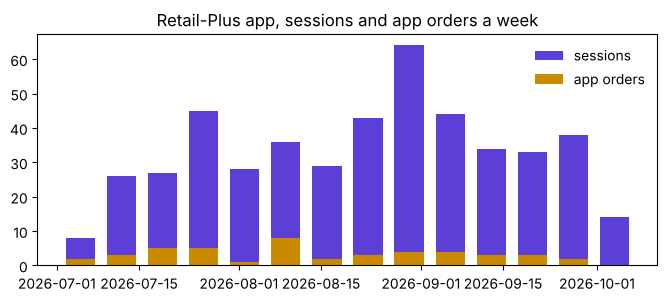

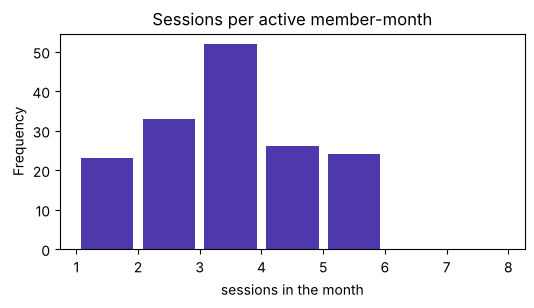

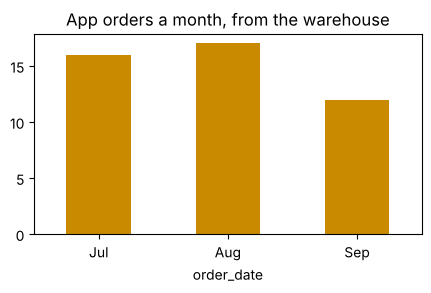

PASS  July to September hold 45 app orders


In [2]:
# Checkouts by customer and day against app orders by customer and day.
co = kev[kev["event_type"] == "checkout"].groupby([kev["customer_id"], kev["event_ts"].dt.date]).size()
od = orders.groupby([orders["customer_id"], orders["order_date"].dt.date]).size()
check("every checkout is one app order on the same day, and every app order has its checkout",
      co.sort_index().to_dict() == od.sort_index().to_dict())
first = kev.groupby("customer_id")["event_ts"].min().dt.date.astype(str)
check("no session before the membership started",
      (first >= mem.set_index("customer_id")["member_since"].reindex(first.index)).all())
check("every session opens with a visit",
      (kev.sort_values("event_ts").groupby("session_id")["event_type"].first() == "visit").all())
# Sessions a week and app orders a week, July to September.
weekly = kev.drop_duplicates("session_id").set_index("event_ts").resample("W-SUN")["session_id"].count()
weekly_orders = orders.set_index("order_date").resample("W-SUN")["order_id"].count()
fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(weekly.index, weekly.values, width=5, color="#5B3FD6", label="sessions")
ax.bar(weekly_orders.index, weekly_orders.values, width=5, color="#C98A00", label="app orders")
ax.legend(frameon=False); ax.set_title("Retail-Plus app, sessions and app orders a week"); plt.show()
sessions_per = kev.drop_duplicates("session_id").groupby(["customer_id", "month"]).size()
ax = sessions_per.plot.hist(bins=range(1, 9), figsize=(6, 2.8), color="#4E38AB", rwidth=0.85)
ax.set_xlabel("sessions in the month"); ax.set_title("Sessions per active member-month"); plt.show()
orders_by_month = orders.groupby(orders["order_date"].dt.strftime("%b"), sort=False).size()
ax = orders_by_month.plot.bar(figsize=(5, 2.6), color="#C98A00", rot=0)
ax.set_title("App orders a month, from the warehouse"); plt.show()
check("July to September hold 45 app orders", len(orders) == 45)

## Is every Retail-Plus cohort falling, and what does blended retention read? (your turn)

Take each member's cohort, the month her membership started, and her active months. Build the
cohort table, then blended retention for July, August and September. The lines to type:

```python
mem["cohort"] = mem["member_since"].str[:7]
active = kev.groupby(["customer_id", "month"]).size().gt(0).rename("active").reset_index()
grid = mem.merge(pd.DataFrame({"month": ["2026-07", "2026-08", "2026-09"]}), how="cross")
grid = grid[grid["cohort"] < grid["month"]].merge(active, on=["customer_id", "month"], how="left")
grid["active"] = grid["active"].fillna(False).astype(bool)
print(grid.pivot_table(index="cohort", columns="month", values="active", aggfunc=["sum", "count"]))
print(grid.groupby("month")["active"].mean().round(3))
```

Then say, cohort by cohort, whether each row falls, which cohort is weakest in its month one,
and how big each cohort is.

## Where in the app is the loss, and when? (your turn)

Add-to-cart to checkout, per session, in three stretches: before 20 August, Monday's comparison
window (20 August to 9 September) and the auto-reorder window (10 to 30 September). The lines
to type:

```python
s = kev.pivot_table(index="session_id", columns="event_type", values="customer_id", aggfunc="size", fill_value=0).gt(0)
s["day"] = kev.groupby("session_id")["event_ts"].min().dt.strftime("%Y-%m-%d")
s["stretch"] = "before"
s.loc[s["day"] >= "2026-08-20", "stretch"] = "comparison"
s.loc[s["day"] >= "2026-09-10", "stretch"] = "window"
carts = s.groupby("stretch")[["add_to_cart", "checkout"]].sum()
print(carts.assign(rate=carts["checkout"] / carts["add_to_cart"]))
```

## Which step can members skip, and which unit does each rate use? (your turn)

Using `s` from the cell above: the share of sessions with no search, and September's checkout
rate counted per session and per member. The lines to type:

```python
print(1 - s["search"].mean())
sep = s[s["day"].str[:7] == "2026-09"].join(kev.drop_duplicates("session_id").set_index("session_id")["customer_id"])
print(sep["checkout"].mean(), sep.groupby("customer_id")["checkout"].any().mean())
```

**What to bring to the TA.** Three sentences: whether it is a cohort problem or an everyone
problem, with the cohort that drives it and its size; the stage that owns the loss, the dates
and the size of the fall; and the unit each of your rates uses. Then answer the head of
Retail-Plus's second question, about the blended number that has not moved, in one line.

**Kavya's review.** "Show me the baseline, show me the evidence, and reach it a second way:
the blend as the weighted average of your cohort rows has to match your direct count."